In [8]:
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay 
import gc
import os
from torch.utils.data import Dataset, DataLoader, Subset
import matplotlib.pyplot as plt
import random
import torch
from torch import nn
import torchaudio
import torchaudio.transforms as T
import torch.nn.functional as F
import IPython.display as ipd
from typing import Dict, List
import math


print(torch.__version__)
print(torch.version.cuda)
print(torchaudio.__version__)
print(torchaudio.list_audio_backends())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

2.6.0+cu124
12.4
2.6.0+cu124
['soundfile']
cuda


In [3]:
class AudioDataset(Dataset):
    def __init__(
        self,
        dir,
        transform=T.MelSpectrogram(
            sample_rate=16000,
            n_mels=64,
            n_fft=1024,
            hop_length=512,
        ),
        fixed_time_frames=None,
    ):
        self.transform = transform
        self.dir = dir
        self.fixed_time_frames = fixed_time_frames
        self.audio_files = []
        self.labels = []
        self.class_names = sorted(os.listdir(dir))

        for label_idx, class_name in enumerate(self.class_names):
            class_path = os.path.join(self.dir, class_name)
            for audio_file in os.listdir(class_path):
                self.audio_files.append(
                    os.path.join(class_path, audio_file)
                )
                self.labels.append(label_idx)

    def __len__(self):
        return len(self.audio_files)

    def __getitem__(self, idx):
        audio_path = self.audio_files[idx]
        label = self.labels[idx]

        waveform, sample_rate = torchaudio.load(audio_path)
        
        if waveform.shape[0] > 1:
            # Усредняем все каналы
            waveform = waveform.mean(dim=0, keepdim=True)
        
        if self.transform is not None:
            waveform = self.transform(waveform)
            # shape: [1, 64, T]

        if self.fixed_time_frames is not None:
            current_frames = waveform.shape[-1]

            if current_frames > self.fixed_time_frames:
                waveform = waveform[:, :, :self.fixed_time_frames]
            else:
                pad_size = self.fixed_time_frames - current_frames
                waveform = torch.nn.functional.pad(
                    waveform,
                    (0, pad_size),
                )

        return waveform, label

    def get_class_name(self, idx):
        return self.class_names[idx]

In [4]:
dataset_temp = AudioDataset("data02")
lengths = []
for i in range(min(100, len(dataset_temp))):
    spec, _ = dataset_temp[i]
    lengths.append(spec.shape[-1])

avg_length = int(np.mean(lengths))
print(f"Средняя длина спектрограммы: {avg_length} кадров")

full_dataset = AudioDataset("data02", fixed_time_frames=avg_length)

total_size = len(full_dataset)
train_size = int(0.7 * total_size)
val_size = int(0.15 * total_size)
test_size = total_size - train_size - val_size
torch.manual_seed(42)
shuffled_indices = torch.randperm(len(full_dataset)).tolist()

train_indices = shuffled_indices[:train_size]
val_indices = shuffled_indices[train_size:train_size+val_size]
test_indices = shuffled_indices[train_size+val_size:]

train_dataset = Subset(full_dataset, train_indices)
val_dataset = Subset(full_dataset, val_indices)
test_dataset = Subset(full_dataset, test_indices)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(train_dataset, batch_size=64, shuffle=False)

print(f"Train: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)}")


Средняя длина спектрограммы: 123 кадров
Train: 15399, Val: 3300, Test: 3301


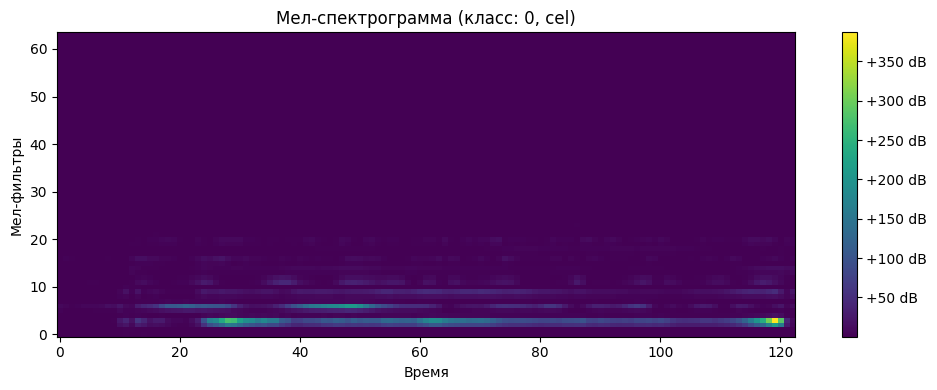

Класс: cel
Индекс в val_dataset: 2
Индекс в full_dataset: 196
Файл: 046__[cel][nod][cla]0034__2.wav


In [4]:
batch_data, batch_labels = next(iter(val_loader))

# Выбор элемента из батча (0-63)
element_idx = 2
spec = batch_data[element_idx, 0]
label = batch_labels[element_idx].item()

class_name = full_dataset.get_class_name(label)

plt.figure(figsize=(10, 4))
plt.imshow(spec.numpy(), origin='lower', aspect='auto', cmap='viridis')
plt.colorbar(format='%+2.0f dB')
plt.title(f'Мел-спектрограмма (класс: {label}, {class_name})')
plt.xlabel('Время')
plt.ylabel('Мел-фильтры')
plt.tight_layout()
plt.show()

original_idx = val_indices[element_idx]
audio_path = full_dataset.audio_files[original_idx]

print(f"Класс: {class_name}")
print(f"Индекс в val_dataset: {element_idx}")
print(f"Индекс в full_dataset: {original_idx}")
print(f"Файл: {os.path.basename(audio_path)}")

waveform, sr = torchaudio.load(audio_path)
ipd.Audio(waveform.numpy(), rate=sr)

In [5]:
class AudioCNN(nn.Module):
    def __init__(self, num_classes: int):
        super().__init__()

        def conv_block(in_channels, out_channels, dropout=0.1):
            return nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),

                nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),

                nn.MaxPool2d(2),
                nn.Dropout2d(dropout),
            )

        self.features = nn.Sequential(
            # [B, 1, 64, 189]
            conv_block(1, 32, dropout=0.05),    # -> [B, 32, 32, 94]
            conv_block(32, 64, dropout=0.10),   # -> [B, 64, 16, 47]
            conv_block(64, 128, dropout=0.15),  # -> [B, 128, 8, 23]
            conv_block(128, 256, dropout=0.20), # -> [B, 256, 4, 11]
            conv_block(256, 512, dropout=0.25), # -> [B, 512, 2, 5]

            # Независимо от размеров входа получаем [B, 512, 1, 1]
            nn.AdaptiveAvgPool2d((1, 1)),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),

            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),

            nn.Linear(128, num_classes),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Если пришёл тензор [B, 64, 189], добавляем размерность канала.
        if x.ndim == 3:
            x = x.unsqueeze(1)

        x = self.features(x)
        x = self.classifier(x)
        return x


class EarlyStopping:
    def __init__(self, patience: int = 5, min_delta: float = 0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.best_score = None
        self.best_state = None
        self.counter = 0

    def step(self, score: float, model: nn.Module) -> bool:
        if self.best_score is None:
            self.best_score = score
            self.best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
            return False

        if score > self.best_score + self.min_delta:
            self.best_score = score
            self.best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
            self.counter = 0
            return False

        self.counter += 1
        return self.counter >= self.patience

    def restore_best(self, model: nn.Module):
        if self.best_state is not None:
            model.load_state_dict(self.best_state)


def accuracy_from_logits(logits: torch.Tensor,
                         y_true: torch.Tensor) -> float:
    preds = torch.argmax(logits, dim=1)
    return (preds == y_true).float().mean().item()


def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()

    total_loss = 0.0
    total_correct = 0
    total_seen = 0

    for x, y in loader:
        x = x.to(device)
        y = y.to(device)

        optimizer.zero_grad(set_to_none=True)

        logits = model(x)
        loss = criterion(logits, y)

        if not torch.isfinite(loss):
            return float("nan"), float("nan")

        loss.backward()
        optimizer.step()

        batch_size = y.size(0)

        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(dim=1) == y).sum().item()
        total_seen += batch_size

    return total_loss / total_seen, total_correct / total_seen


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_seen = 0

    for x, y in loader:
        x = x.to(device)
        y = y.to(device)

        logits = model(x)
        loss = criterion(logits, y)

        if not torch.isfinite(loss):
            return float("nan"), float("nan")

        batch_size = y.size(0)

        total_loss += loss.item() * batch_size
        total_correct += (logits.argmax(dim=1) == y).sum().item()
        total_seen += batch_size

    return total_loss / total_seen, (total_correct / total_seen) 


def fit(
    model,
    train_loader,
    val_loader,
    optimizer,
    criterion,
    device,
    epochs: int = 30,
    verbose: bool = True,
    early_stopping: EarlyStopping = None,
):
    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
    }

    for epoch in range(1, epochs + 1):
        tr_loss, tr_acc = train_one_epoch(
            model, train_loader, optimizer, criterion, device
        )
        val_loss, val_acc = evaluate(
            model, val_loader, criterion, device
        )

        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        if verbose:
            print(
                f"Epoch {epoch:02d}/{epochs} | "
                f"train loss {tr_loss:.4f}, acc {tr_acc:.4f} | "
                f"val loss {val_loss:.4f}, acc {val_acc:.4f}"
            )

        if (not math.isfinite(tr_loss)) or (not math.isfinite(val_loss)):
            print("NaN/Inf обнаружены в loss. Обучение остановлено.")
            break

        if early_stopping is not None:
            if early_stopping.step(val_acc, model):
                if verbose:
                    print(
                        f"Early stopping на эпохе {epoch}. "
                        f"Лучший val_acc = {early_stopping.best_score:.4f}"
                    )
                early_stopping.restore_best(model)
                break

    return history


def plot_history(hist: Dict[str, List[float]], title: str = ""):
    epochs = range(1, len(hist["train_loss"]) + 1)

    # Loss
    plt.figure(figsize=(10, 4))
    plt.plot(epochs, hist["train_loss"], label="train loss")
    plt.plot(epochs, hist["val_loss"], label="val loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"{title} | Loss")
    plt.grid(True)
    plt.legend()
    plt.show()

    # Accuracy
    plt.figure(figsize=(10, 4))
    plt.plot(epochs, hist["train_acc"], label="train accuracy")
    plt.plot(epochs, hist["val_acc"], label="val accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(f"{title} | Accuracy")
    plt.grid(True)
    plt.legend()
    plt.show()

def plot_confusion_matrix(model, dataloader, device, class_names=None):
    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for x, y in dataloader:
            x = x.to(device)
            y = y.to(device)

            outputs = model(x)
            preds = torch.argmax(outputs, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(y.cpu().numpy())

    # считаем confusion matrix
    cm = confusion_matrix(all_labels, all_preds)

    # визуализация
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    
    fig, ax = plt.subplots(figsize=(6, 6))
    disp.plot(ax=ax, cmap="Blues", colorbar=True)
    plt.title("Confusion Matrix")
    plt.show()


@torch.no_grad()
def predict_audio(
    model,
    file_path: str,
    fixed_time_frames: int = 123,
    class_names: list[str] = ["cel", "cla", "flu", "gac", "gel", "org", "pia", "sax", "trs", "tru", "vio"],
    device: str = "cuda",
    sample_rate: int = 16000,
    n_mels: int = 64,
    n_fft: int = 1024,
    hop_length: int = 512,
    top_k: int = 1,
    show_spectrogram: bool = True,
):
    """
    Выполняет предсказание для одного аудиофайла.

    Параметры:
    ----------
    model : nn.Module
        Обученная модель.
    file_path : str
        Путь к .wav файлу.
    class_names : list[str]
        Список названий классов (например full_dataset.class_names).
    fixed_time_frames : int
        Длина спектрограммы, использовавшаяся при обучении (avg_length).
    device : str
        "cuda" или "cpu".
    top_k : int
        Сколько наиболее вероятных классов показать.
    show_spectrogram : bool
        Отображать ли mel-спектрограмму.

    Возвращает:
    -----------
    pred_idx : int
        Индекс предсказанного класса.
    pred_class : str
        Название предсказанного класса.
    pred_proba : float
        Вероятность предсказанного класса.
    probs : torch.Tensor
        Вектор вероятностей по всем классам.
    """

    # Переводим модель в режим оценки
    model.eval()
    model.to(device)

    # Загружаем аудио
    waveform, sr = torchaudio.load(file_path)

    # Если sample rate отличается — ресемплируем
    if sr != sample_rate:
        waveform = torchaudio.transforms.Resample(sr, sample_rate)(waveform)
        sr = sample_rate

    # Если стерео — переводим в моно
    if waveform.shape[0] > 1:
        waveform = waveform.mean(dim=0, keepdim=True)

    # Создаём MelSpectrogram (как в обучении)
    mel_transform = torchaudio.transforms.MelSpectrogram(
        sample_rate=sample_rate,
        n_mels=n_mels,
        n_fft=n_fft,
        hop_length=hop_length,
    )

    spec = mel_transform(waveform)

    # Подгоняем длину по времени
    if spec.shape[-1] > fixed_time_frames:
        spec = spec[:, :, :fixed_time_frames]
    else:
        pad_size = fixed_time_frames - spec.shape[-1]
        spec = torch.nn.functional.pad(spec, (0, pad_size))

    # Визуализация спектрограммы
    if show_spectrogram:
        plt.figure(figsize=(10, 4))
        plt.imshow(
            torch.log(spec[0] + 1e-6).cpu().numpy(),
            aspect="auto",
            origin="lower",
        )
        plt.title("Log-Mel Spectrogram")
        plt.xlabel("Time Frames")
        plt.ylabel("Mel Bins")
        plt.colorbar()
        plt.show()

    # Добавляем batch dimension: [1, 1, 64, T]
    spec = spec.unsqueeze(0).to(device)

    # Прямой проход
    logits = model(spec)

    # Вероятности
    probs = F.softmax(logits, dim=1)[0]

    # Предсказание
    pred_idx = torch.argmax(probs).item()
    pred_class = class_names[pred_idx]
    pred_proba = probs[pred_idx].item()

    # Top-K предсказаний
    top_k = min(top_k, len(class_names))
    top_probs, top_indices = torch.topk(probs, k=top_k)

    print(f"\nФайл: {file_path}")
    print(f"Предсказанный класс: {pred_class}")
    print(f"Вероятность: {pred_proba:.4f}\n")

    print("Top predictions:")
    for rank, (idx, prob) in enumerate(zip(top_indices.tolist(),
                                           top_probs.tolist()), 1):
        print(f"{rank:>2}. {class_names[idx]:<20} {prob:.4f}")

    return pred_idx, pred_class, pred_proba, probs.cpu()

Epoch 01/100 | train loss 2.2656, acc 0.1790 | val loss 2.1137, acc 0.2497
Epoch 02/100 | train loss 2.0546, acc 0.2764 | val loss 1.9084, acc 0.3364
Epoch 03/100 | train loss 1.8489, acc 0.3576 | val loss 1.6760, acc 0.4370
Epoch 04/100 | train loss 1.7120, acc 0.4238 | val loss 1.5750, acc 0.4761
Epoch 05/100 | train loss 1.5777, acc 0.4722 | val loss 1.6040, acc 0.4488
Epoch 06/100 | train loss 1.4631, acc 0.5169 | val loss 1.3261, acc 0.5621
Epoch 07/100 | train loss 1.3474, acc 0.5563 | val loss 1.2772, acc 0.5703
Epoch 08/100 | train loss 1.2531, acc 0.5876 | val loss 1.2158, acc 0.5991
Epoch 09/100 | train loss 1.1728, acc 0.6186 | val loss 1.1823, acc 0.6097
Epoch 10/100 | train loss 1.1012, acc 0.6422 | val loss 1.1505, acc 0.6167
Epoch 11/100 | train loss 1.0333, acc 0.6635 | val loss 1.0359, acc 0.6621
Epoch 12/100 | train loss 0.9684, acc 0.6876 | val loss 1.0629, acc 0.6436
Epoch 13/100 | train loss 0.9134, acc 0.7050 | val loss 1.0942, acc 0.6470
Epoch 14/100 | train loss

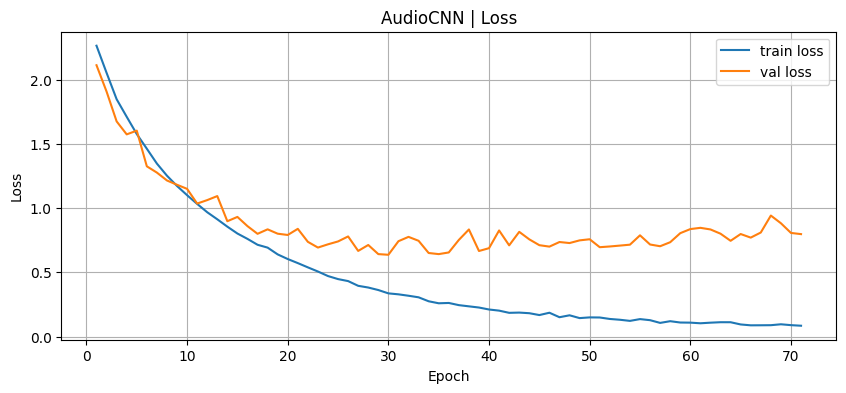

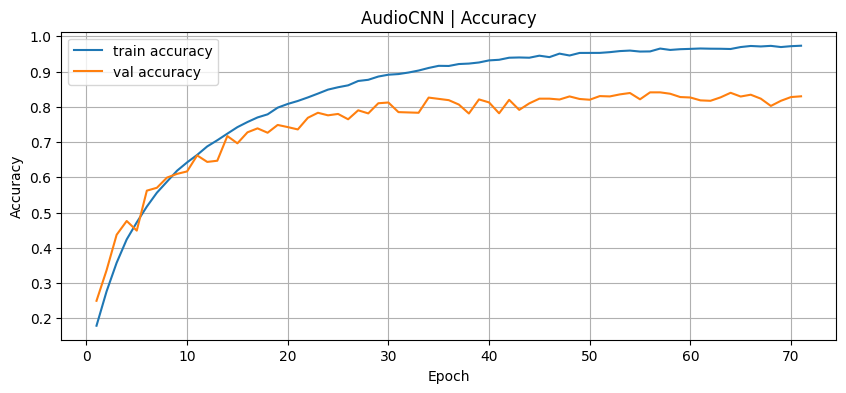

In [23]:
model = AudioCNN(num_classes=11).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=5e-4)
early_stopping = EarlyStopping(patience=15)
history = fit(
    model,
    train_loader,
    val_loader,
    optimizer,
    criterion,
    device=device,
    epochs=100,
    early_stopping=early_stopping,
)
plot_history(history, "AudioCNN")

In [37]:
test_loss, test_acc = evaluate(
    model, test_loader, criterion, device
)
print(f"Test loss: {test_loss:.4f}, Test accuracy: {test_acc:.4f}")

Test loss: 0.0232, Test accuracy: 0.9332


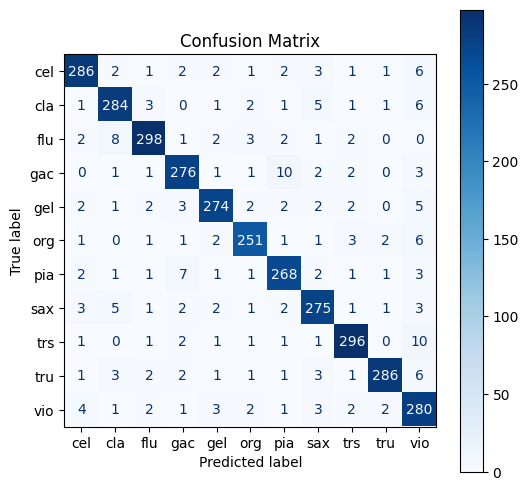

In [45]:
plot_confusion_matrix(model, test_loader, device, full_dataset.class_names)

In [42]:
torch.save(model.state_dict(), "bestMusCl.pt")

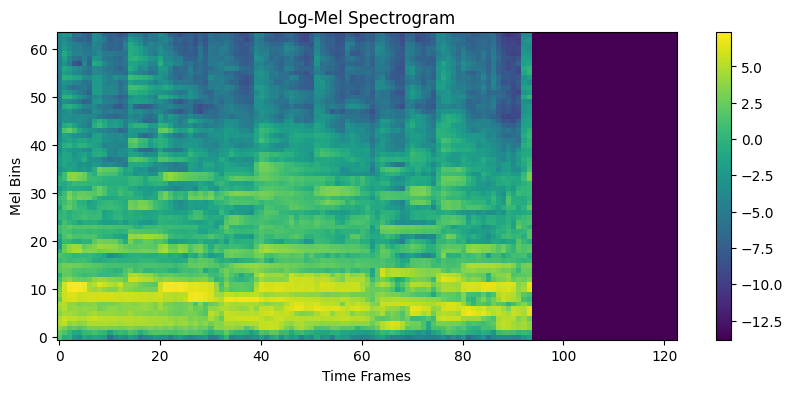


Файл: dataTest/Guitar(gac).wav
Предсказанный класс: gac
Вероятность: 0.9569

Top predictions:
 1. gac                  0.9569


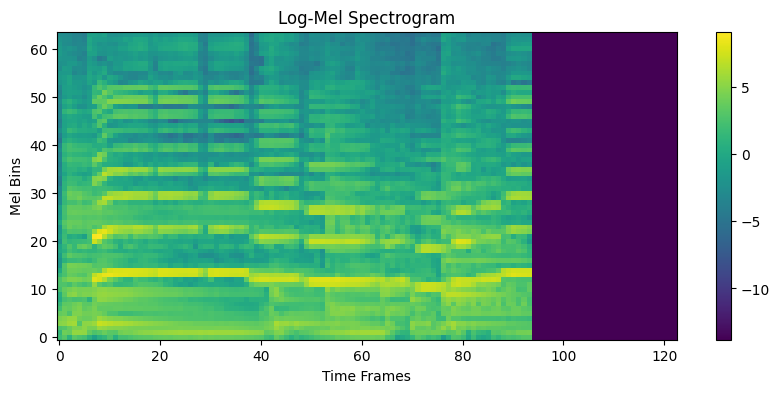


Файл: dataTest/Saxophone(sax).wav
Предсказанный класс: sax
Вероятность: 0.9999

Top predictions:
 1. sax                  0.9999


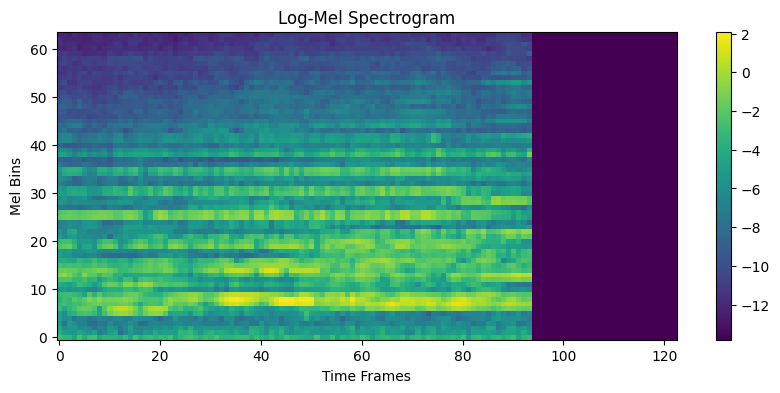


Файл: dataTest/Violin(vio).wav
Предсказанный класс: vio
Вероятность: 0.8398

Top predictions:
 1. vio                  0.8398


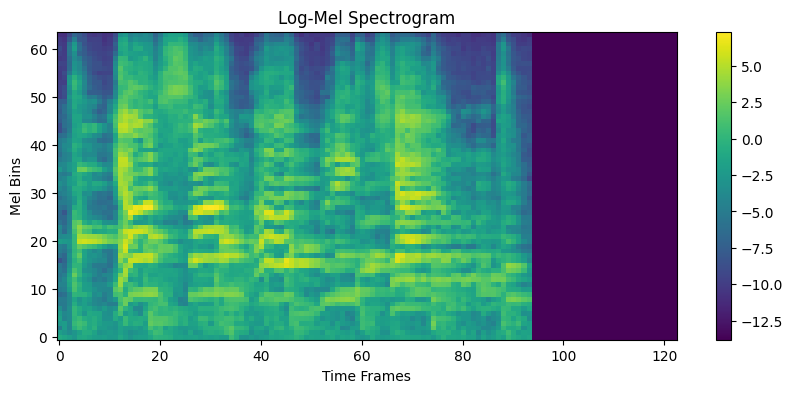


Файл: dataTest/Trash(trs).wav
Предсказанный класс: trs
Вероятность: 0.9937

Top predictions:
 1. trs                  0.9937


In [19]:
model = AudioCNN(num_classes=11).to(device)
model.load_state_dict(torch.load("artifacts/bestMusCl.pt"))
pred_idx, pred_class, pred_proba, probs = predict_audio(
    model=model,
    file_path="dataTest/Guitar(gac).wav",
)
pred_idx, pred_class, pred_proba, probs = predict_audio(
    model=model,
    file_path="dataTest/Saxophone(sax).wav",
)
pred_idx, pred_class, pred_proba, probs = predict_audio(
    model=model,
    file_path="dataTest/Violin(vio).wav",
)
pred_idx, pred_class, pred_proba, probs = predict_audio(
    model=model,
    file_path="dataTest/Trash(trs).wav",
)